# 29 · Replicate the phase comparison on new sources

Evaluate 12 fresh 40-image galleries. Each contains four examples per digit. Exclude all pilot test sources and exact image duplicates before sampling. Preserve the eight original perturbation conditions. The primary contrast is aligned local Q minus aligned Q magnitude on source-excluded same-digit top-1.

The fresh primary contrast reproduces the orientation-phase gain: 64.79% for aligned Q versus 53.93% for aligned Q magnitude. The paired gain is 10.86 percentage points (95% interval 8.12–13.78).

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage8 import BASELINES,FROZEN,PRIMARY,VIEWS,contrast
OUT=ROOT/'results'/'stage8'
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
summary=pd.read_csv(OUT/'summary.csv')
decisions=pd.read_csv(OUT/'decisions.csv.gz')

## Fixed contrasts
Each query can find one source in 40 candidates, or any of three same-digit alternatives in 39 source-excluded candidates. Chance is 1/40 and 3/39. Use paired gallery-bootstrap intervals, conditional on the new balanced galleries. The secondary uniform-profile check repeats one predeclared Stage 7 omission, dropping the triplet coordinate. Methods and weights are held fixed.

In [3]:
m=pd.read_csv(OUT/'membership.csv')
assert len(m.query("panel=='replication'"))==480
assert m.query("panel=='replication'").groupby(['gallery','label']).size().eq(4).all()
assert set(m.query("panel=='pilot'").source).isdisjoint(m.query("panel=='replication'").source)
full=decisions.query("panel=='replication' and gallery_type=='full'")
z=summary.query("panel=='replication' and gallery_type=='full'").set_index('method')
methods=[*PRIMARY,'aligned ZNCC','HOG after ZNCC','aligned structure tensor',
         'ResNet-50 cosine','EfficientNet-B0 cosine','uniform profile','uniform minus triplets']
display((100*z.loc[methods,['identity','class']]).round(2))
comparisons=[('aligned local Q',r) for r in ['aligned Q magnitude','aligned pixels',
                                             'aligned structure tensor','aligned ZNCC','HOG after ZNCC']]
comparisons.append(('uniform minus triplets','uniform profile'))
rows=[(a,b,ep,*contrast(full,a,b,ep)) for a,b in comparisons for ep in ['identity','class']]
intervals=pd.DataFrame(rows,columns=['left','right','endpoint','difference','low95','high95'])
display(intervals.round(4));intervals.to_csv(OUT/'replication_contrasts.csv',index=False)

,identity,class
method,,
aligned local Q,95.26,64.79
local Q,84.43,63.18
aligned pixels,93.91,52.27
aligned Q magnitude,92.47,53.93
aligned gradient strength,67.45,37.68
aligned ZNCC,92.81,55.70
HOG after ZNCC,87.03,50.23
aligned structure tensor,95.16,62.50
ResNet-50 cosine,61.46,38.88


,left,right,endpoint,difference,low95,high95
0,aligned local Q,aligned Q magnitude,identity,0.0279,0.0229,0.0326
1,aligned local Q,aligned Q magnitude,class,0.1086,0.0812,0.1378
2,aligned local Q,aligned pixels,identity,0.0135,0.0094,0.0172
3,aligned local Q,aligned pixels,class,0.1253,0.0958,0.1544
4,aligned local Q,aligned structure tensor,identity,0.0010,-0.0013,0.0036
5,aligned local Q,aligned structure tensor,class,0.0229,0.0094,0.0354
6,aligned local Q,aligned ZNCC,identity,0.0245,0.0211,0.0276
7,aligned local Q,aligned ZNCC,class,0.0909,0.0659,0.1159
8,aligned local Q,HOG after ZNCC,identity,0.0823,0.0742,0.0909
9,aligned local Q,HOG after ZNCC,class,0.1456,0.1266,0.1701


## Isolate the distractor composition
Construct two same-size comparisons within the same fresh galleries. Keep all three same-label examples. The hard panel adds the 16 wrong-label images nearest to the clean query in 7 × 7 average-pooled pixel distance. The random panel adds 16 wrong-label images drawn with a fixed seed. Both have 19 candidates and chance 3/19. All methods see the same subsets. The clean query is used only to construct the challenge, not to score any candidate.

This defines hardness under a coarse-pixel criterion. It can favor or disfavor particular representations, so treat it as a secondary stress test.

gallery_type,hard 19,random 19,hard minus random
method,,,
aligned local Q,68.39,75.44,-7.06
local Q,66.64,72.14,-5.49
aligned pixels,54.51,63.46,-8.96
aligned Q magnitude,56.51,64.06,-7.55
aligned gradient strength,43.57,47.76,-4.19
aligned ZNCC,58.70,66.20,-7.50
HOG after ZNCC,55.96,62.53,-6.56
aligned structure tensor,66.28,73.20,-6.93
ResNet-50 cosine,46.33,50.60,-4.27


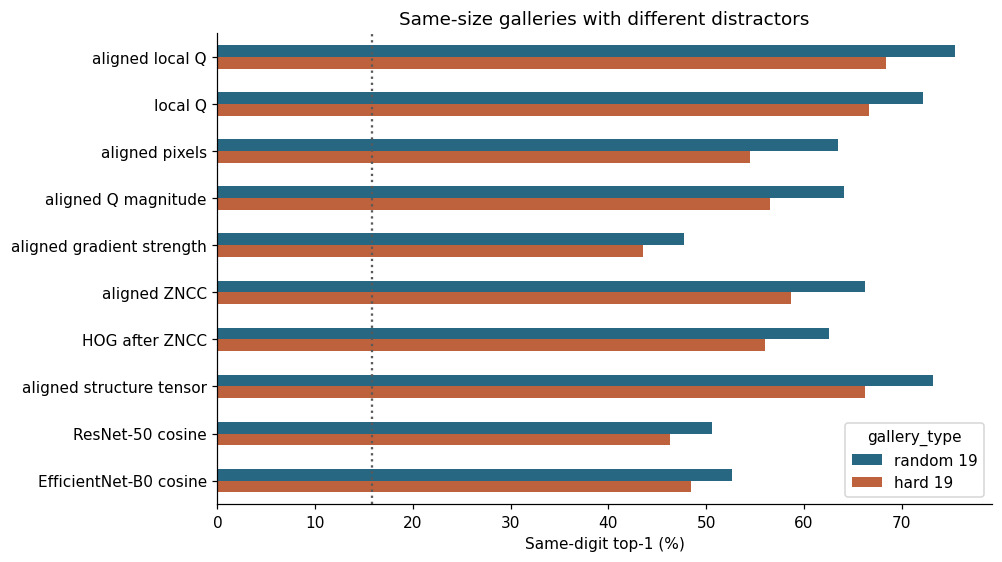

In [5]:
short=summary.query("panel=='replication' and gallery_type!='full'")
by=short.pivot(index='method',columns='gallery_type',values='class').loc[methods]
by['hard minus random']=by['hard 19']-by['random 19']
display((by*100).round(2))
by.to_csv(OUT/'hard_distractor_summary.csv')
fig,ax=plt.subplots(figsize=(9,5))
plot=by.iloc[:10][['random 19','hard 19']]*100
plot.plot.barh(ax=ax,color=['#286782','#bd623d'])
ax.axvline(300/19,color='.35',ls=':')
ax.set(xlabel='Same-digit top-1 (%)',ylabel='',title='Same-size galleries with different distractors')
ax.invert_yaxis();show('29_hard_distractors')

Interpret the phase ablation against the matched search and the stronger classical baselines. The full-gallery replication changes both the number of distractors and the number of relevant samples. The equal-size challenge changes the wrong-digit composition while holding the relevant candidates fixed.